# 01 · Data, roughness buckets, and how much the finer grids add

**Project:** PK-2026-011, *Learning Physical Dynamics Across Resolutions* (Group 2)

This is the first of five notebooks. Run them in order:

| Notebook | What it does | Run time |
|---|---|---|
| **01_data_and_roughness** (this one) | Checks the data, builds the roughness buckets, shows the start-time confound, and measures how much *new* detail each finer grid contains | < 1 min |
| 02a_train_cnn | Defines and trains the CNN: 3 training grids × 3 seeds = 9 runs, with live convergence plots | ~8 min |
| 02b_train_fno | Defines and trains the FNO: 3 training grids × 3 seeds = 9 runs, with live convergence plots | ~45 min |
| 03_evaluation | Every table and the two report figures (Part 1: promised checks; Part 2: training-resolution experiment) | ~1 min |
| 04_figures | A visual tour: the plots from `bucked_based_eval` adapted to the final models, plus Part 2 visuals | ~1 min |

This notebook trains nothing. It only looks at the data, because two of our report's arguments
are really statements about the data:
1. *"Rough inputs come mostly from early start times"* (the confound we have to control for).
2. *"At a 128-point training grid, the 256/512-point grids add almost nothing new"* (the reason we need the training-resolution experiment).

**Requirements:** `pip install numpy pandas matplotlib torch jupyter`

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# The notebooks live in aml-group2/experiments/, the data in aml-group2/data/
DATA = os.path.join("..", "data")

pd.set_option("display.precision", 3)

## 1. What is in the data files

Each `.npz` file holds three arrays we use:

- `field`: the solution **now**, $u(x, t)$, one row per example.
- `target`: the solution **one stored time step later**, $u(x, t+\Delta t)$. This is what the models must predict.
- `context`: two numbers per example: the start-time label and the viscosity (always 0.01).

Training set: 48 trajectories × 5 start times = **240 examples**, on a 128-point grid.
Evaluation set: 12 different trajectories × 5 start times = **60 examples**, given on 128, 256 and 512 points.

The rows are ordered **trajectory by trajectory**: rows 0–4 are trajectory 0 at its five start times,
rows 5–9 are trajectory 1, and so on. We use this later to resample whole trajectories in the bootstrap.

In [2]:
train = np.load(os.path.join(DATA, "train.npz"))
ev = {N: np.load(os.path.join(DATA, f"eval_{N}.npz")) for N in (128, 256, 512)}

print("train  field:", train["field"].shape, " target:", train["target"].shape)
for N in (128, 256, 512):
    print(f"eval {N}: field:", ev[N]["field"].shape)

# The start-time label of the first 10 evaluation rows: it cycles 0, .2, .4, .6, .8 -> trajectory-major order
print("\nstart-time labels of rows 0-9:", ev[128]["context"][:10, 0])
print("viscosity values present:     ", np.unique(ev[128]["context"][:, 1]))

train  field: (240, 128)  target: (240, 128)
eval 128: field: (60, 128)
eval 256: field: (60, 256)
eval 512: field: (60, 512)

start-time labels of rows 0-9: [0.  0.2 0.4 0.6 0.8 0.  0.2 0.4 0.6 0.8]
viscosity values present:      [0.01]


### The coarser grids are exact subsamples of the finer ones

The kit made every grid by keeping every k-th point of one 1024-point simulation. So the 128-point
evaluation input should be **exactly** every 4th point of the 512-point one, and the 256-point input every 2nd point.

This matters for the report in two ways:
- The grids differ **only in sampling density**, not in solver resolution. Our claim is about grid sensitivity, not about a new simulation (a limitation to state).
- Because they are exact subsamples, we can make *any* coarser grid ourselves (64, 32 points) by taking every 8th / 16th point. Part 2 relies on this.

In [3]:
u512 = ev[512]["field"]
print("eval_128 == eval_512[:, ::4] :", np.array_equal(ev[128]["field"], u512[:, ::4]))
print("eval_256 == eval_512[:, ::2] :", np.array_equal(ev[256]["field"], u512[:, ::2]))
print("same for targets             :", np.array_equal(ev[128]["target"], ev[512]["target"][:, ::4]))

eval_128 == eval_512[:, ::4] : True
eval_256 == eval_512[:, ::2] : True
same for targets             : True


## 2. Measuring roughness: three measures

Every test input needs one number that says how rough it is. There is no single correct definition of "rough",
so we use **one primary measure and two checks**. If all three lead to the same conclusion, the result does not
depend on how we happened to define roughness. All three are computed on the **128-point input**, the grid the models
were trained on.

**1. Total variation (primary measure)**
- **What it is:** add up every jump between neighbouring points, wrapping around at the end because the domain is
  periodic:
  $$R_{\mathrm{TV}}(u) = \sum_{i=1}^{N} |u_{i+1} - u_i|, \qquad u_{N+1} := u_1 .$$
- **How it behaves:** every wiggle adds to it, and so does a taller wave. Many oscillations or a steep front give a
  large value; a gentle wave gives a small one.
- **Why it is the primary measure:** it is the standard way to measure how much a function varies (Harten, 1997), it is
  simple to explain, and we **pre-registered it in M2**. Switching the main measure after seeing the results would look
  like picking whichever measure gives the nicest answer.

**2. Sharpness (main robustness check)**
- **What it is:** the typical slope divided by the typical size of the fluctuations
  (taken from the group notebook `bucked_based_eval.ipynb`):
  $$R_{\mathrm{sharp}}(u) = \frac{\mathrm{RMS}(\partial_x u)}{\mathrm{RMS}(u - \bar u)} .$$
- **How it behaves:** dividing by the size of the wave **cancels its height**. What is left is how short the
  wavelengths are. For a pure sine wave with $k$ cycles across the domain, $R_{\mathrm{sharp}} \approx 2\pi k$, so it is
  a kind of typical wavenumber. Doubling a wave's height doubles total variation but leaves sharpness unchanged.
- **Why it is our main check:**
  - It ranks the inputs **quite differently** from total variation, because it ignores height. Getting the same answer
    under it is a real test, not a re-run.
  - It matches the mechanism: our hypothesis is about **fine-scale content**, and our error (relative $L^2$) also divides
    out the wave's size.
  - It is **less tied to start time** than total variation (section 3), so it also helps with the confound.
- **Why it is not primary:** it was added after M2, so it was not pre-registered.
- **Does the grid matter?** No. Measured on the 128-, 256- or 512-point input, it puts every input in the same bucket
  (checked below). We use 128 so that all three measures describe the same input.

**3. Max slope (the check promised in M2)**
- **What it is:** the single largest jump between neighbouring points:
  $$R_{\max}(u) = \max_i |u_{i+1} - u_i| .$$
- **How it behaves:** it only looks at the steepest spot. One sharp front scores high even if the rest of the field is
  smooth; many moderate wiggles score low.
- **Why we use it:** total variation cannot tell "many small wiggles" from "one sharp front", and Burgers solutions are
  all about sharp fronts. We **promised this check in M2**, so it has to be reported.
- **Why it is only a minor check:** it ranks the inputs almost the same way as total variation (both grow with the
  wave's height), so it adds little new information. It also depends on a single point, so it is noisier.

In [4]:
def total_variation(u):
    # np.roll(u, -1, axis=1) shifts every row one step left, so element i becomes u[i+1]
    # (and the last element wraps to u[0]: the periodic boundary)
    return np.abs(np.roll(u, -1, axis=1) - u).sum(axis=1)

def sharpness(u):
    # RMS slope / RMS fluctuation; slope by central differences on a periodic grid of spacing dx = 1/N
    u = u.astype(np.float64)
    dx = 1.0 / u.shape[1]
    slope = (np.roll(u, -1, axis=1) - np.roll(u, 1, axis=1)) / (2 * dx)
    fluct = u - u.mean(axis=1, keepdims=True)              # remove the mean: only the wiggles count
    return np.sqrt((slope ** 2).mean(axis=1)) / np.sqrt((fluct ** 2).mean(axis=1))

def max_slope(u):
    # the largest single jump between neighbouring points
    return np.abs(np.roll(u, -1, axis=1) - u).max(axis=1)

u128 = ev[128]["field"]          # all three measures use the 128-point input
tv = total_variation(u128)
sh = sharpness(u128)
ms = max_slope(u128)

**A quick check of how the measures behave.** On the 128-point grid, a pure sine wave with $k$ cycles should have
sharpness about $2\pi k$ (a little less for many cycles, because the slope is estimated from neighbouring grid points).
If we double every input's height, total variation and max slope should double while sharpness stays the same.

In [5]:
x128 = np.linspace(0, 1, 128, endpoint=False)
for k in (1, 3, 10):
    print(f"sine with {k:>2} cycles: sharpness = {sharpness(np.sin(2 * np.pi * k * x128)[None])[0]:6.2f}   (2*pi*k = {2 * np.pi * k:6.2f})")

print("\ndouble every input's height:")
print("  total variation changes by a factor %.2f" % np.mean(total_variation(2 * u128) / tv))
print("  sharpness       changes by a factor %.2f" % np.mean(sharpness(2 * u128) / sh))
print("  max slope       changes by a factor %.2f" % np.mean(max_slope(2 * u128) / ms))

sine with  1 cycles: sharpness =   6.28   (2*pi*k =   6.28)
sine with  3 cycles: sharpness =  18.78   (2*pi*k =  18.85)
sine with 10 cycles: sharpness =  60.34   (2*pi*k =  62.83)

double every input's height:
  total variation changes by a factor 2.00
  sharpness       changes by a factor 1.00
  max slope       changes by a factor 2.00


### Three buckets per measure

For each measure we sort the 60 test inputs and cut them into three equal groups of 20:
**smooth** (bucket 0), **medium** (1) and **rough** (2). The cut is made once, before any model is evaluated, and
every example keeps its bucket on every grid.

In [6]:
def tertile_buckets(score):
    # argsort gives the order from smoothest to roughest; array_split cuts it into 3 groups of 20
    order = np.argsort(score, kind="stable")
    bucket = np.empty(len(score), dtype=int)
    for k, idx in enumerate(np.array_split(order, 3)):
        bucket[idx] = k
    return bucket

MEASURES = {"total variation": tv, "sharpness": sh, "max slope": ms}
BUCKETS = {name: tertile_buckets(score) for name, score in MEASURES.items()}
B_TV = BUCKETS["total variation"]          # the primary buckets, used everywhere below
NAMES = ["smooth", "medium", "rough"]

s = np.sort(tv)
print("total-variation cut-offs: %.3f and %.3f" % ((s[19] + s[20]) / 2, (s[39] + s[40]) / 2))
print("examples per bucket:", np.bincount(B_TV))

# sharpness on the finer grids gives the same buckets as on 128 points
for N in (256, 512):
    same = np.mean(tertile_buckets(sharpness(ev[N]["field"])) == BUCKETS["sharpness"])
    print(f"sharpness buckets from the {N}-point input match the 128-point ones for {100 * same:.0f}% of inputs")

total-variation cut-offs: 0.748 and 2.148
examples per bucket: [20 20 20]
sharpness buckets from the 256-point input match the 128-point ones for 100% of inputs
sharpness buckets from the 512-point input match the 128-point ones for 100% of inputs


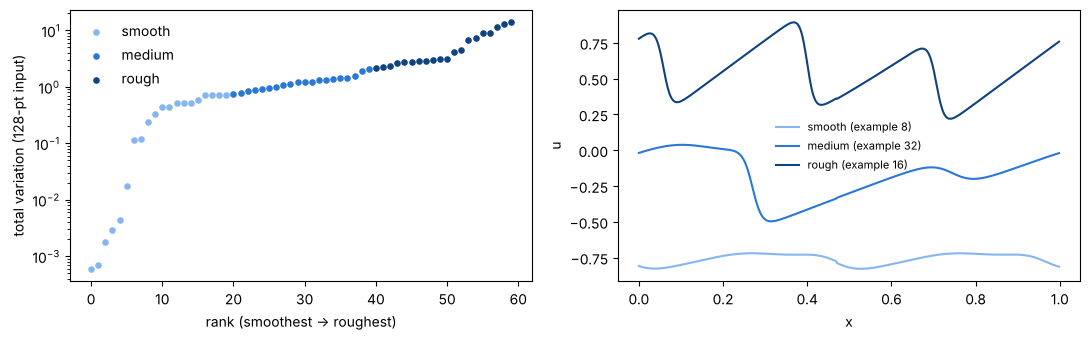

In [7]:
# Left: every input's total variation, sorted, coloured by bucket. Right: one typical input per bucket.
COLORS = ["#86b6ef", "#2a78d6", "#104281"]          # light -> dark = smooth -> rough
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))

order = np.argsort(tv)
for k in range(3):
    pos = np.flatnonzero(B_TV[order] == k)
    axes[0].scatter(pos, tv[order][pos], s=14, color=COLORS[k], label=NAMES[k])
axes[0].set_yscale("log"); axes[0].set_xlabel("rank (smoothest → roughest)")
axes[0].set_ylabel("total variation (128-pt input)"); axes[0].legend(frameon=False)

x = np.linspace(0, 1, 512, endpoint=False)
for k in range(3):
    idx = np.flatnonzero(B_TV == k)
    mid = idx[np.argsort(tv[idx])[len(idx) // 2]]      # the median-roughness example of this bucket
    axes[1].plot(x, u512[mid], color=COLORS[k], label=f"{NAMES[k]} (example {mid})")
axes[1].set_xlabel("x"); axes[1].set_ylabel("u"); axes[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

### How much do the three measures agree?

Two ways to compare them:
- **Spearman rank correlation:** the ordinary correlation between the two *rankings* of the 60 inputs.
  1 means both measures put the inputs in exactly the same order.
- **Same bucket:** how often both measures put an input in the same third.

In [8]:
def spearman(a, b):
    rank = lambda v: np.argsort(np.argsort(v))     # rank of each value: 0 = smallest
    return np.corrcoef(rank(a), rank(b))[0, 1]

pairs = [("total variation", "sharpness"), ("total variation", "max slope"), ("sharpness", "max slope")]
display(pd.DataFrame([dict(pair=f"{a} vs {b}",
                           spearman=spearman(MEASURES[a], MEASURES[b]),
                           same_bucket=f"{100 * np.mean(BUCKETS[a] == BUCKETS[b]):.0f}%") for a, b in pairs]))

,pair,spearman,same_bucket
0,total variation vs sharpness,0.396,60%
1,total variation vs max slope,0.896,73%
2,sharpness vs max slope,0.289,47%


**Reading it.** Total variation and max slope agree closely (both grow with the wave's height), so max slope is a
weak check. Sharpness ranks the inputs quite differently, because it ignores height. That makes it the
**more independent** check: if the conclusion survives under sharpness as well, it is not an artefact of measuring amplitude.

## 3. The start-time confound

Each input comes from one of five start times. Burgers solutions **smooth out over time** (viscosity
diffuses the sharp parts), so rough inputs come mainly from early start times. That is a problem for
our claim: if rough inputs had larger error growth, it could be because they are rough *or* because they are early.

The table counts how many inputs of each total-variation bucket come from each start time. Notebook 03 controls
for this with a regression that compares inputs **within** the same start time.

In [9]:
start = ev[128]["context"][:, 0]
table = pd.DataFrame({NAMES[k]: [int(np.sum((start == t) & (B_TV == k))) for t in np.unique(start)]
                      for k in range(3)}, index=[f"label {t:.1f}" for t in np.unique(start)])
display(table)

,smooth,medium,rough
label 0.0,0,0,12
label 0.2,2,2,8
label 0.4,3,9,0
label 0.6,5,7,0
label 0.8,10,2,0


**How tied to start time is each measure?** Below: the rank correlation of each measure with start time, and how many
of the 20 *rough* inputs come from each start time. The closer the correlation is to 0, and the more spread out the
rough bucket is, the better that measure separates "rough" from "early".

In [10]:
times = np.unique(start)
t_tiebreak = start + 1e-6 * np.arange(60)    # start time has only 5 values: a tiny increasing number breaks ties
display(pd.DataFrame({name: [f"{spearman(score, t_tiebreak):.2f}"]
                            + [int(np.sum((start == t) & (BUCKETS[name] == 2))) for t in times]
                      for name, score in MEASURES.items()},
                     index=["Spearman with start time"] + [f"rough inputs at label {t:.1f}" for t in times]))

,total variation,sharpness,max slope
Spearman with start time,-0.82,-0.60,-0.67
rough inputs at label 0.0,12,9,8
rough inputs at label 0.2,8,8,7
rough inputs at label 0.4,0,3,2
rough inputs at label 0.6,0,0,2
rough inputs at label 0.8,0,0,1


Total variation is the most tied to start time: its rough bucket comes **only** from the first two start times.
Both checks are less tied. Sharpness and max slope each put a few later-start-time inputs in their rough bucket, and
their correlation with start time is weaker. So if the result is the same under all three measures, it is less likely
to be an "early-time" effect in disguise. This is a second, independent answer to the confound, next to the regression
in notebook 03.

> **Note on the start-time labels.** The kit labels the five start times 0, 0.2, 0.4, 0.6, 0.8.
> The appendix at the end fits the PDE to the data and finds one stored step = 0.01 time units.
> The inputs are stored indices 0/40/80/120/160, which would be t = 0, 0.4, 0.8, 1.2, 1.6.
> Check this before writing physical times in the report. "The first two start times" is safe either way.

## 4. How much do the finer grids actually add?

This section is the reason for Part 2 of the experiments.

**Fourier modes in one paragraph.** Any periodic field can be written as a sum of waves
$\hat u_k e^{2\pi i k x}$. The wavenumber $k$ counts how many cycles fit in the domain: low $k$ is the broad
shape, high $k$ is fine detail and steep fronts. A grid of $N$ points can only represent wavenumbers up to
$N/2$, the **Nyquist** wavenumber. Anything finer is invisible on that grid.

So when a model trained on 128 points is evaluated on 512 points, the *only* genuinely new information is
the part of the field with $k \ge 64$. We measure it in two ways, on the 512-point evaluation data:

1. **Input energy above the training Nyquist:** the fraction of $\sum_k |\hat u_k|^2$ that sits at $k \ge N_{\text{train}}/2$.
2. **Truncation reference error:** take the 512-point *target*, delete every mode with $k \ge N_{\text{train}}/2$,
   and compute the relative $L^2$ error of that cut-off version against the full target. This is the error a
   *perfect* model would get if it could not produce any detail finer than its training grid.
   It is our yardstick for "how much is there to fail on".

We compute both for training grids of 128, 64 and 32 points.

In [11]:
def rel_l2(pred, target):
    # relative L2 error per example: ||pred - target|| / ||target||
    return np.linalg.norm(pred - target, axis=1) / np.linalg.norm(target, axis=1)

def band_limit(u, kmax):
    # keep only wavenumbers 0 .. kmax-1, then transform back to the grid
    U = np.fft.rfft(u.astype(np.float64), axis=1)
    U[:, kmax:] = 0
    return np.fft.irfft(U, n=u.shape[1], axis=1)

x512 = ev[512]["field"].astype(np.float64)
y512 = ev[512]["target"].astype(np.float64)
E = np.abs(np.fft.rfft(x512, axis=1)) ** 2          # energy per wavenumber (rfft: k = 0 .. 256)

rows = []
for n_train in (128, 64, 32):
    k_nyq = n_train // 2
    frac = E[:, k_nyq:].sum(1) / E.sum(1)                       # share of input energy the training grid can't see
    trunc = rel_l2(band_limit(y512, k_nyq), y512)               # truncation reference error
    for k in range(3):
        sel = B_TV == k
        rows.append(dict(training_grid=n_train, bucket=NAMES[k],
                         energy_above_nyquist=np.median(frac[sel]),
                         truncation_error_x1e3=1e3 * trunc[sel].mean()))
unseen = pd.DataFrame(rows)
display(unseen.pivot(index="training_grid", columns="bucket", values="truncation_error_x1e3")[NAMES]
        .style.format("{:.2f}").set_caption("Truncation reference error (×10⁻³)"))
display(unseen.pivot(index="training_grid", columns="bucket", values="energy_above_nyquist")[NAMES]
        .style.format("{:.1e}").set_caption("Median share of input energy above the training Nyquist"))

bucket,smooth,medium,rough
training_grid,,,
32,0.41,9.22,25.35
64,0.16,1.10,6.30
128,0.11,0.44,2.47


bucket,smooth,medium,rough
training_grid,,,
32,4.5e-08,1.2e-05,9.7e-05
64,1.4e-08,2.0e-07,9.6e-06
128,6.9e-09,7.4e-08,1.4e-06


**How to read this.** With a 128-point training grid, the truncation reference is only about
0.1 / 0.4 / 2.5 ×10⁻³. Compare that with the FNO's own error at 128 points (about 0.4 / 1.2 / 10.6 ×10⁻³, notebook 03):
the unseen part is tiny next to the error the model already makes. So "the FNO's error does not grow on rough
inputs" could simply mean *there is nothing new to fail on*.

Training at 32 points raises the rough bucket's unseen content about **10×** (to ~25 ×10⁻³). If the FNO's
resolution transfer really depends on roughness, it should show there. That is the Part 2 experiment.

## Appendix: which Burgers equation is this?

The report should state the exact equation (brief, question 1). PDEBench writes viscous Burgers as

$$\partial_t u + \partial_x\!\left(\tfrac{u^2}{2}\right) = \frac{\nu}{\pi}\,\partial_{xx} u, \qquad x \in [0,1) \text{ periodic},$$

so the diffusion coefficient is $\nu/\pi \approx 0.0032$, not $\nu = 0.01$. We check this directly. We take the
later-time inputs (smooth enough to simulate accurately on 512 points), step them forward with a standard
spectral solver for several candidate time steps and diffusion coefficients, and see which combination
reproduces the stored targets. The solver is a textbook pseudo-spectral RK4. You don't need to follow its
details, only the result.

In [12]:
def solve_burgers(u, dt, D, n_sub=200):
    # advance u_t + (u^2/2)_x = D u_xx by time dt, in n_sub small RK4 steps, using FFT derivatives
    N = u.shape[1]
    k = 2 * np.pi * np.fft.rfftfreq(N, 1 / N)            # angular wavenumbers on [0, 1)
    dealias = np.fft.rfftfreq(N, 1 / N) < N / 3          # standard 2/3 rule against aliasing in u^2
    def rhs(U):
        w = np.fft.irfft(U, n=N, axis=1)
        return -1j * k * np.fft.rfft(0.5 * w * w, axis=1) * dealias - D * k ** 2 * U
    U, h = np.fft.rfft(u.astype(np.float64), axis=1), dt / n_sub
    for _ in range(n_sub):
        k1 = rhs(U); k2 = rhs(U + h / 2 * k1); k3 = rhs(U + h / 2 * k2); k4 = rhs(U + h * k3)
        U = U + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
    return np.fft.irfft(U, n=N, axis=1)

late = start >= 0.4                                     # smoother inputs: easier to simulate accurately
rows = []
for D_name, D in [("0", 0.0), ("ν/π", 0.01 / np.pi), ("ν", 0.01)]:
    for dt in (0.005, 0.01, 0.02):
        err = rel_l2(solve_burgers(x512[late], dt, D), y512[late]).mean()
        rows.append(dict(diffusion=D_name, dt=dt, error_x1e3=1e3 * err))
display(pd.DataFrame(rows).pivot(index="diffusion", columns="dt", values="error_x1e3")
        .style.format("{:.2f}").set_caption("Solver vs stored target, relative L2 (×10⁻³): lowest = the true setting"))

dt,0.005000,0.010000,0.020000
diffusion,,,
0,6.69,4.90,15.87
ν,7.17,7.88,18.69
ν/π,5.60,0.52,11.12


The smallest error by far (about 0.5 ×10⁻³) is at **diffusion = ν/π and Δt = 0.01**, so the data follow the
PDEBench convention above, with one stored step of 0.01 time units. Put this exact equation in the report's
problem formulation.